# IS 455 Final Project — Promotion-Driven Revenue Drift

**Student:** Rasheed Adigun  
**Course:** IS 455 — Database Design & Prototyping  
**Stack:** DuckDB · Python ETL (`build.py`, `data_generate.py`) · **pandas** · NumPy · Matplotlib · Jupyter — **bonus:** vector retrieval + GraphRAG (`ai.*` in DuckDB)

---

## 1. Problem

| Stakeholder view | What goes wrong |
|------------------|-----------------|
| **Business** | Leadership compares “campaign-attributed GMV” week over week to judge lift. |
| **Analytics** | The same order can be touched twice with identical keys; joining touches to order-line GMV **multiplies rows** so `SUM(revenue)` looks artificially high. |
| **Operations** | Marketing sends **batch 1** then a **corrected batch 2** (deduped touches, new validity window, late touches). Reports must update **without** silently mixing inconsistent logic. |

**Curated grain (assignment):** one row = `(order_id, campaign_id, purchase_date)` in `curated.fct_promo_attributed_gmv`.

---

## 2. Solution (high level)

1. **Evidence layer (`raw`)** — keep files as landed, including duplicates and batch ids.  
2. **Hygiene layer (`staging`)** — types, business filters, **pre-aggregated order GMV**, **deduped touches** (safe join protocol: pre-aggregate before joining).  
3. **Publish layer (`curated`)** — deterministic equal-split attribution + reporting view.  
4. **Trust layer (`meta`)** — run history, audit checks, checksum idempotency, stage latency.  
5. **Augmented rebuild** — recompute only an affected **date window** when batch 2 arrives.  
6. **AI bonus** — chunks + vectors in DuckDB, RAG eval, `note_edges` + GraphRAG eval, grounded answers.


In [1]:
# --- Run this cell first (or use Kernel > Restart & Run All) ---
import importlib.util
import subprocess
import sys

def _ensure_matplotlib():
    if importlib.util.find_spec("matplotlib") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
    import matplotlib.pyplot as plt
    return plt

plt = _ensure_matplotlib()
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
from pathlib import Path
import duckdb
import pandas as pd

DB_PATH = Path("data/processed/warehouse.duckdb")
if not DB_PATH.exists():
    raise FileNotFoundError(
        "Missing warehouse. From project root run:\n"
        "  python data_generate.py --root .\n"
        "  ./run_demo.sh   (or the four build.py commands in README.md)\n"
        f"Expected file: {DB_PATH.resolve()}"
    )
con = duckdb.connect(str(DB_PATH))
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True
print("OK — connected to", DB_PATH)
display(
    con.sql("""
    SELECT run_id, mode, scope, status, rows_curated, audit_failures
    FROM meta.runs
    ORDER BY started_at_ms DESC
    LIMIT 6
    """).df()
)


OK — connected to data/processed/warehouse.duckdb


,run_id,mode,scope,status,rows_curated,audit_failures
0,2026-11-22T01:00:47.438,full,ALL,SUCCESS,10,0
1,2026-11-22T01:00:47.274,full,ALL,SUCCESS,10,0
2,2026-11-22T01:00:47.108,augmented,"purchase_date=[2018-01-03,2018-01-05]",SUCCESS,10,0
3,2026-11-22T01:00:46.945,full,ALL,SUCCESS,8,0


### What this output means
Each row is one **pipeline run** from `meta.runs`: build **mode** (`full` vs `augmented`), **scope** (all data vs a date window), **status**, how many **curated rows** were produced, and **audit_failures**. This is the monitoring spine you use to prove which run is current and whether quality gates passed.

## Pipeline design & demo flow

This project uses **audit-first ETL** in `build.py`: layered SQL blocks (`STAGING_SQL`, `CURATED_SQL`, `CURATED_AUGMENTED_SQL`, `CHECKS_SQL`), **templated** checks via `run_sql_template(...)` (run id + date windows), outputs to `meta.runs` and `meta.audit_results`, **checksum idempotency** in `meta.row_count_reconciliation`, and **`EXCEPT` reconciliation** in `R2_lost_curated_grain_keys` when `--strict-audit` is enabled.

**Demo order (this notebook):** raw evidence → staging → curated → charts → user-facing output → failure scenario → audits & idempotency → full vs incremental → monitoring → AI & grounding → closing takeaway.


## Raw Layer: Base Evidence

The **Raw Layer** contains data as received, including anomalies.

- Preserves duplicates/corrections for auditability
- Includes source batch metadata (`source_batch_id`)
- Allows trace-back to exact landed records

For this project:
- Olist-like base tables are loaded into `raw.orders`, `raw.order_items`, `raw.payments`, etc.
- Promo files are loaded from `batch_id=1` and `batch_id=2` into `raw.campaigns` and `raw.campaign_touches`.

**Why keep bad rows here:** duplicates and batch ids remain visible so downstream layers and `meta.audit_results` can **prove** cleaning and attribution rules, not hide them.

,table_name,row_count
0,raw.campaign_touches,19
1,raw.campaigns,6
2,raw.order_items,10
3,raw.orders,8
4,raw.payments,8


,order_id,campaign_id,touch_at,n
0,o1004,cmp20,2018-01-03 12:02:00,3
1,o1001,cmp10,2018-01-02 09:00:00,2
2,o1001,cmp20,2018-01-02 09:10:00,2
3,o1002,cmp20,2018-01-02 12:05:00,2
4,o1003,cmp30,2018-01-03 07:00:00,2
5,o1004,cmp10,2018-01-03 12:00:00,2
6,o1005,cmp30,2018-01-04 08:00:00,2
7,o1008,cmp10,2018-01-05 19:50:00,2


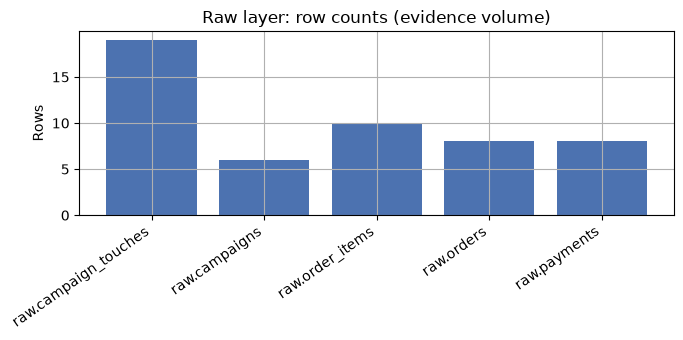

Figure: volume by raw table — promo touches include duplicate keys before staging fix.


In [2]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Raw-layer live inspection
raw_counts = con.sql('''
SELECT 'raw.orders' AS table_name, COUNT(*) AS row_count FROM raw.orders
UNION ALL SELECT 'raw.order_items', COUNT(*) FROM raw.order_items
UNION ALL SELECT 'raw.payments', COUNT(*) FROM raw.payments
UNION ALL SELECT 'raw.campaigns', COUNT(*) FROM raw.campaigns
UNION ALL SELECT 'raw.campaign_touches', COUNT(*) FROM raw.campaign_touches
ORDER BY table_name
''').df()

display(raw_counts)

# Show injected failure evidence in raw promo touches
raw_dups = con.sql('''
SELECT order_id, campaign_id, touch_at, COUNT(*) AS n
FROM raw.campaign_touches
GROUP BY 1,2,3
HAVING COUNT(*) > 1
ORDER BY n DESC, order_id
''').df()

display(raw_dups)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(raw_counts["table_name"], raw_counts["row_count"], color="#4C72B0")
ax.set_title("Raw layer: row counts (evidence volume)")
ax.set_ylabel("Rows")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
print("Figure: volume by raw table — promo touches include duplicate keys before staging fix.")


### What this output means
**Row counts** show all raw tables loaded into DuckDB. The **duplicate-groups** table lists `(order_id, campaign_id, touch_at)` keys that appear more than once in `raw.campaign_touches`—that is the **injected failure** (noisy marketing logs) **before** staging fixes cardinality.

## Staging Layer: Standardize + Dedupe + Join-Safety

Staging responsibilities in this project:

- Normalize types (`TIMESTAMP`, `DATE`, numeric casts)
- Filter invalid keys / enforce deterministic business filters
- Build `stg_order_gmv` as order-level truth before campaign joins
- Detect duplicate touches in `staging.dq_touch_dup_candidates`
- Dedupe touches in `staging.stg_touches_dedup` using deterministic `ROW_NUMBER()` rule

This is where we prevent many-to-many multiplication from silently inflating downstream sums.

,table_name,row_count
0,staging.dq_touch_dup_candidates,8
1,staging.stg_order_gmv,8
2,staging.stg_order_items,10
3,staging.stg_orders,8
4,staging.stg_touches_dedup,10
5,staging.stg_touches_raw,19


,raw_touch_rows,dedup_touch_rows,duplicate_key_groups
0,19,10,8


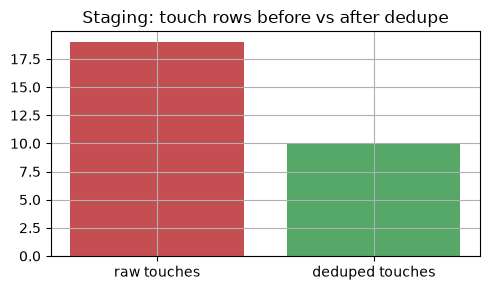

Figure: 8 duplicate key groups flagged in dq_touch_dup_candidates.


In [3]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Staging-layer live inspection
staging_counts = con.sql('''
SELECT 'staging.stg_orders' AS table_name, COUNT(*) AS row_count FROM staging.stg_orders
UNION ALL SELECT 'staging.stg_order_items', COUNT(*) FROM staging.stg_order_items
UNION ALL SELECT 'staging.stg_order_gmv', COUNT(*) FROM staging.stg_order_gmv
UNION ALL SELECT 'staging.stg_touches_raw', COUNT(*) FROM staging.stg_touches_raw
UNION ALL SELECT 'staging.stg_touches_dedup', COUNT(*) FROM staging.stg_touches_dedup
UNION ALL SELECT 'staging.dq_touch_dup_candidates', COUNT(*) FROM staging.dq_touch_dup_candidates
ORDER BY table_name
''').df()

display(staging_counts)

# Show dedupe impact
dedupe_impact = con.sql('''
SELECT
  (SELECT COUNT(*) FROM staging.stg_touches_raw)   AS raw_touch_rows,
  (SELECT COUNT(*) FROM staging.stg_touches_dedup) AS dedup_touch_rows,
  (SELECT COUNT(*) FROM staging.dq_touch_dup_candidates) AS duplicate_key_groups
''').df()

display(dedupe_impact)
di = dedupe_impact.iloc[0]
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["raw touches", "deduped touches"], [di["raw_touch_rows"], di["dedup_touch_rows"]], color=["#C44E52", "#55A868"])
ax.set_title("Staging: touch rows before vs after dedupe")
plt.tight_layout()
plt.show()
print(f"Figure: {int(di['duplicate_key_groups'])} duplicate key groups flagged in dq_touch_dup_candidates.")


### What this output means
**Counts** compare raw touch rows vs **deduped** touches and how many **duplicate key groups** were flagged. The chart contrasts **raw vs deduped** touch volume: the drop is intentional—**one row per logical touch** before joining to GMV so `SUM` cannot explode.

## Curated Layer: Reporting-Ready Contract

Curated table: `curated.fct_promo_attributed_gmv`  
Declared grain: **(order_id, campaign_id, purchase_date)**

Business-ready view: `curated.vw_promo_impact_daily`

Design tradeoff used:
- Equal-split allocation across campaigns touching an order/day
- Chosen for deterministic reproducibility and explainability during audits

In [4]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Curated-layer live inspection
fact_preview = con.sql('''
SELECT *
FROM curated.fct_promo_attributed_gmv
ORDER BY purchase_date, order_id, campaign_id
LIMIT 25
''').df()

daily_preview = con.sql('''
SELECT *
FROM curated.vw_promo_impact_daily
ORDER BY purchase_date, campaign_id
''').df()

display(fact_preview)
display(daily_preview)

# Grain check: ensure uniqueness at declared grain
grain_violations = con.sql('''
SELECT order_id, campaign_id, purchase_date, COUNT(*) AS n
FROM curated.fct_promo_attributed_gmv
GROUP BY 1,2,3
HAVING COUNT(*) > 1
''').df()

display(grain_violations)

,order_id,campaign_id,purchase_date,attributed_gmv,touch_count,campaign_count,dq_inflation_risk
0,o1001,cmp10,2018-01-02,62.5,1,2,True
1,o1001,cmp20,2018-01-02,62.5,1,2,True
2,o1002,cmp20,2018-01-02,80.0,1,1,True
3,o1003,cmp30,2018-01-03,160.0,1,1,True
4,o1004,cmp10,2018-01-03,47.5,1,2,True
5,o1004,cmp20,2018-01-03,47.5,1,2,True
6,o1005,cmp30,2018-01-04,120.0,1,1,True
7,o1006,cmp20,2018-01-04,50.0,1,1,False
8,o1007,cmp30,2018-01-05,40.0,1,1,False
9,o1008,cmp10,2018-01-05,210.0,1,1,True


,purchase_date,campaign_id,total_attributed_gmv,risky_gmv,order_count
0,2018-01-02,cmp10,62.5,62.5,1
1,2018-01-02,cmp20,142.5,142.5,2
2,2018-01-03,cmp10,47.5,47.5,1
3,2018-01-03,cmp20,47.5,47.5,1
4,2018-01-03,cmp30,160.0,160.0,1
5,2018-01-04,cmp20,50.0,0.0,1
6,2018-01-04,cmp30,120.0,120.0,1
7,2018-01-05,cmp10,210.0,210.0,1
8,2018-01-05,cmp30,40.0,0.0,1


,order_id,campaign_id,purchase_date,n


### What this output means
The **fact** preview is at grain `(order_id, campaign_id, purchase_date)`. The **view** aggregates **attributed GMV** for analysts. The **grain check** should be **empty**: if it had rows, you would have duplicate keys at the declared grain (audit failure).

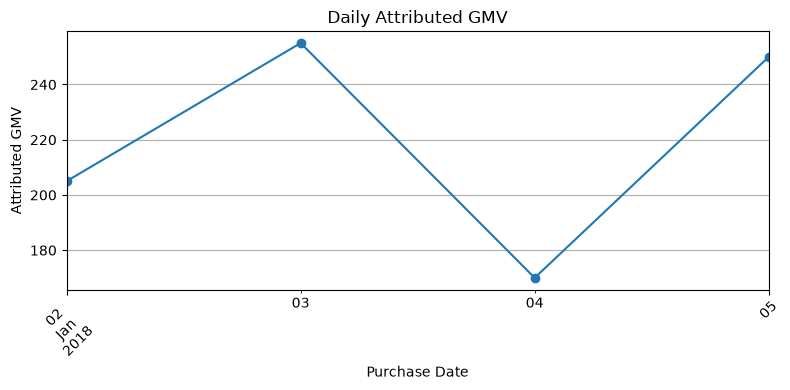

,purchase_date,total_gmv
0,2018-01-02,205.0
1,2018-01-03,255.0
2,2018-01-04,170.0
3,2018-01-05,250.0


In [5]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Visualization 1: daily attributed GMV trend
trend = con.sql('''
SELECT purchase_date, SUM(total_attributed_gmv) AS total_gmv
FROM curated.vw_promo_impact_daily
GROUP BY 1
ORDER BY 1
''').df()

ax = trend.plot(x='purchase_date', y='total_gmv', kind='line', marker='o', figsize=(8,4), legend=False)
ax.set_title('Daily Attributed GMV')
ax.set_xlabel('Purchase Date')
ax.set_ylabel('Attributed GMV')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

trend

### What this chart means
**Daily attributed GMV** from `vw_promo_impact_daily`: business trend after **dedupe + attribution rules**. Use it to narrate “what the pipeline publishes,” not raw order totals.

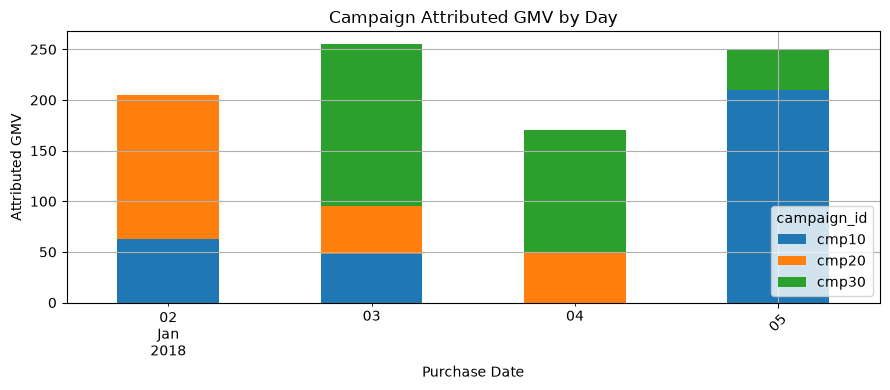

campaign_id,cmp10,cmp20,cmp30
purchase_date,,,
2018-01-02,62.5,142.5,0.0
2018-01-03,47.5,47.5,160.0
2018-01-04,0.0,50.0,120.0
2018-01-05,210.0,0.0,40.0


In [6]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Visualization 2: campaign contributions by date (stacked bars)
camp = con.sql('''
SELECT purchase_date, campaign_id, total_attributed_gmv
FROM curated.vw_promo_impact_daily
ORDER BY purchase_date, campaign_id
''').df()

pivot = camp.pivot(index='purchase_date', columns='campaign_id', values='total_attributed_gmv').fillna(0)
ax = pivot.plot(kind='bar', stacked=True, figsize=(9,4))
ax.set_title('Campaign Attributed GMV by Day')
ax.set_xlabel('Purchase Date')
ax.set_ylabel('Attributed GMV')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

pivot

### What this chart means
**Stacked bars** split that daily GMV by **campaign_id**: shows **mix** (which campaigns drive the total each day) on top of the same attribution logic.

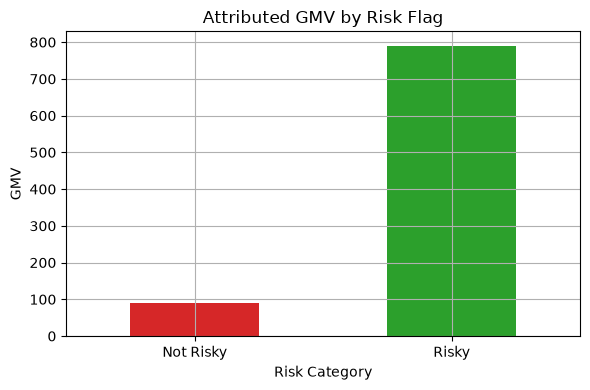

,risk_label,gmv
0,Not Risky,90.0
1,Risky,790.0


In [7]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Visualization 3: risky vs non-risky attributed GMV
risk = con.sql('''
SELECT
  CASE WHEN dq_inflation_risk THEN 'Risky' ELSE 'Not Risky' END AS risk_label,
  SUM(attributed_gmv) AS gmv
FROM curated.fct_promo_attributed_gmv
GROUP BY 1
''').df()

ax = risk.plot(x='risk_label', y='gmv', kind='bar', figsize=(6,4), legend=False, color=['#d62728', '#2ca02c'])
ax.set_title('Attributed GMV by Risk Flag')
ax.set_xlabel('Risk Category')
ax.set_ylabel('GMV')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

risk

### What this chart means
**Risky vs not risky** sums `attributed_gmv` where `dq_inflation_risk` is true vs false—rows tied to **duplicate-touch patterns** in raw are flagged so analysts know where attribution leaned on **corrected** staging logic.

## User-facing output (required)

- **User:** Growth / Marketing Analyst
- **Output surface:** `curated.vw_promo_impact_daily` (DuckDB view)
- **Refresh behavior:** per build run (daily batch workflow); staleness and scope are visible in `meta.runs` (`mode`, `scope`, `status`, timestamps)

## Failure scenario: duplicate promotional touches

### How introduced
`data_generate.py` injects duplicate logical touches in promo batch 1 (same `order_id`, `campaign_id`, `touch_at`).

### Where detected
`staging.dq_touch_dup_candidates` detects duplicated key groups.

### What staging does
`staging.stg_touches_dedup` keeps deterministic winners using `ROW_NUMBER()`.

### What curated does
`curated.fct_promo_attributed_gmv` is built from deduped touches and flags risk via `dq_inflation_risk`.

Without staging dedupe, many-to-many joins would silently inflate attributed GMV.

,raw_touch_rows,dedup_touch_rows,duplicate_groups_detected,curated_risk_flag_rows
0,19,10,8,8


Result: duplicate groups are detected in staging, deduped before curated attribution, and surfaced as risk flags.


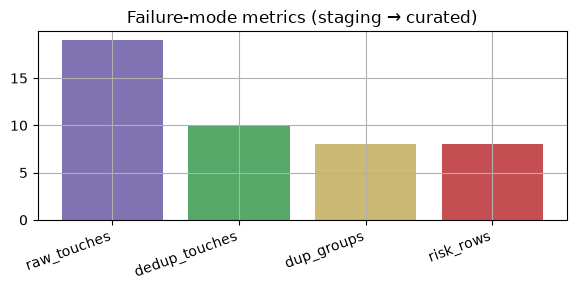

In [8]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Failure scenario evidence
failure_story = con.sql('''
SELECT
  (SELECT COUNT(*) FROM staging.stg_touches_raw) AS raw_touch_rows,
  (SELECT COUNT(*) FROM staging.stg_touches_dedup) AS dedup_touch_rows,
  (SELECT COUNT(*) FROM staging.dq_touch_dup_candidates) AS duplicate_groups_detected,
  (SELECT COUNT(*) FROM curated.fct_promo_attributed_gmv WHERE dq_inflation_risk) AS curated_risk_flag_rows
''').df()

display(failure_story)

print('Result: duplicate groups are detected in staging, deduped before curated attribution, and surfaced as risk flags.')
fs = failure_story.iloc[0]
fig, ax = plt.subplots(figsize=(6, 3))
parts = ["raw_touches", "dedup_touches", "dup_groups", "risk_rows"]
vals = [fs["raw_touch_rows"], fs["dedup_touch_rows"], fs["duplicate_groups_detected"], fs["curated_risk_flag_rows"]]
ax.bar(parts, vals, color=["#8172B2", "#55A868", "#CCB974", "#C44E52"])
ax.set_title("Failure-mode metrics (staging → curated)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### What this output means
One summary row: **raw** touch count, **deduped** count, **duplicate groups detected**, and **curated rows still flagged** as inflation risk. It ties the **failure story** to measurable staging and curated outcomes.

## Idempotency & audit evidence

### Latest run
This section explicitly reports:
- build mode (`full` vs `augmented`)
- status (`SUCCESS`/`FAILED`)
- curated rows produced
- audit failure count

### Audit checks
You should see each check name with PASS/FAIL and metric values.

### Idempotency (checksums)
Interpretation rule:
- `checksum_versions = 1` -> idempotent
- `checksum_versions > 1` -> inconsistency

### Pipeline Latency (Performance Insight)
Goal: Show runtime behavior.

Use stage timings to identify bottlenecks and explain where optimization effort would go first.

,run_id,mode,scope,status,rows_curated,audit_failures
0,2026-11-22T01:00:47.438,full,ALL,SUCCESS,10,0


Mode: full
Status: SUCCESS
Rows produced: 10
Audit failures: 0


,check_name,status,metric_value,details
0,C1_curated_key_not_null,PASS,0.0,null rows in curated key columns
1,C2_duplicate_touch_detection,PASS,8.0,duplicate logical touches detected in staging ...
2,C3_curated_grain_uniqueness,PASS,0.0,duplicate rows at declared curated grain
3,R1_attributed_not_exceed_order_gmv,PASS,0.0,violating order count
4,R2_lost_curated_grain_keys,PASS,0.0,expected grain keys missing in curated
5,graphrag_eval_hit_at_1,PASS,1.0,minimum expected GraphRAG Hit@1 >= 0.66
6,retrieval_eval_hit_at_1,PASS,1.0,minimum expected Hit@1 >= 0.66


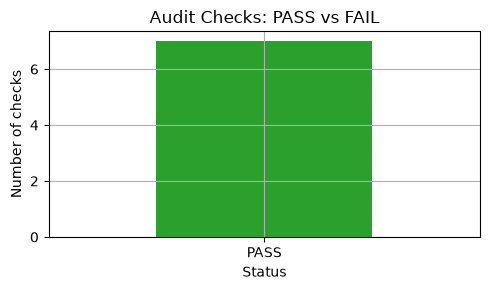

Interpretation: All checks passed -> audit gate indicates reliable run output.


,table_name,checksum_versions
0,curated.fct_promo_attributed_gmv,1
1,staging.stg_order_items,1
2,staging.stg_orders,1
3,staging.stg_touches_dedup,1


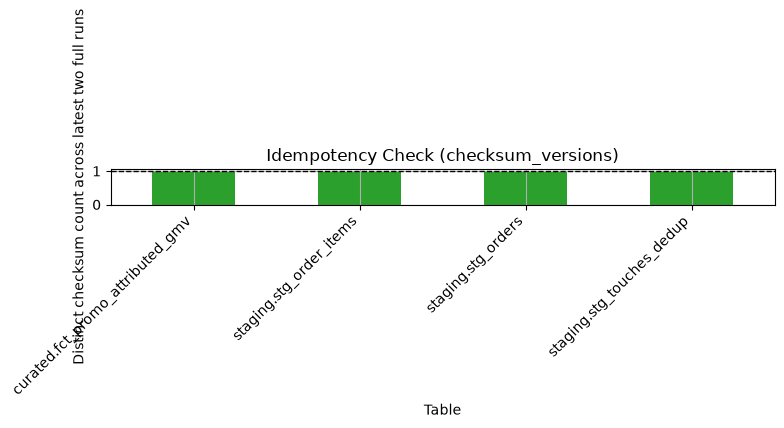

Interpretation: checksum_versions = 1 for all tracked tables -> idempotent full rebuild.


,stage_name,elapsed_ms
0,raw_load,9
1,staging,7
2,curated,3
3,audit_reconcile,8
4,ai_pipeline,12


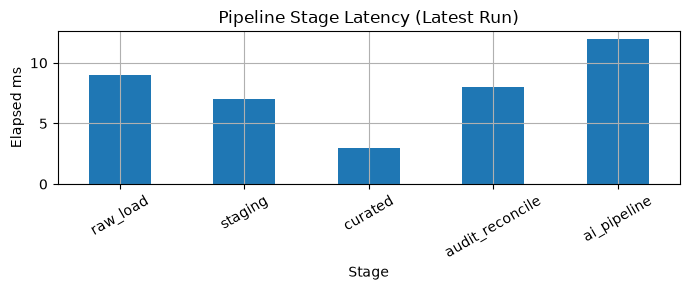

Slowest stage: ai_pipeline (12 ms)
Interpretation: optimize this stage first if runtime becomes a bottleneck.


In [9]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Latest pipeline run summary
latest_run = con.sql('''
SELECT run_id, mode, scope, status, rows_curated, audit_failures
FROM meta.runs
ORDER BY started_at_ms DESC
LIMIT 1
''').df()

display(latest_run)
latest_run_id = latest_run.iloc[0]['run_id']

print('Mode:', latest_run.iloc[0]['mode'])
print('Status:', latest_run.iloc[0]['status'])
print('Rows produced:', int(latest_run.iloc[0]['rows_curated']))
print('Audit failures:', int(latest_run.iloc[0]['audit_failures']))

# Audit check results
latest_checks = con.sql(f"""
SELECT check_name, status, metric_value, details
FROM meta.audit_results
WHERE run_id = '{latest_run_id}'
ORDER BY check_name
""").df()

display(latest_checks)

# Visualization: pass vs fail checks
status_counts = latest_checks.groupby('status', as_index=False).size()
ax = status_counts.plot(x='status', y='size', kind='bar', legend=False, figsize=(5,3), color=['#2ca02c' if s == 'PASS' else '#d62728' for s in status_counts['status']])
ax.set_title('Audit Checks: PASS vs FAIL')
ax.set_xlabel('Status')
ax.set_ylabel('Number of checks')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if (status_counts['status'] == 'FAIL').any():
    print('Interpretation: One or more checks failed -> data reliability risk exists.')
else:
    print('Interpretation: All checks passed -> audit gate indicates reliable run output.')

# Idempotency verification
idempotency = con.sql('''
WITH latest_two_full AS (
  SELECT run_id
  FROM meta.runs
  WHERE mode='full' AND status='SUCCESS'
  ORDER BY started_at_ms DESC
  LIMIT 2
)
SELECT table_name, COUNT(DISTINCT checksum) AS checksum_versions
FROM meta.row_count_reconciliation
WHERE run_id IN (SELECT run_id FROM latest_two_full)
GROUP BY table_name
ORDER BY table_name
''').df()

display(idempotency)

# Visualization: idempotency status per table
idempotency['idempotent_flag'] = idempotency['checksum_versions'].apply(lambda x: 1 if x == 1 else 0)
ax = idempotency.plot(x='table_name', y='checksum_versions', kind='bar', figsize=(8,3), legend=False, color=['#2ca02c' if v == 1 else '#d62728' for v in idempotency['checksum_versions']])
ax.axhline(1, color='black', linestyle='--', linewidth=1)
ax.set_title('Idempotency Check (checksum_versions)')
ax.set_xlabel('Table')
ax.set_ylabel('Distinct checksum count across latest two full runs')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

if (idempotency['checksum_versions'] > 1).any():
    print('Interpretation: checksum_versions > 1 found -> NOT idempotent for at least one table.')
else:
    print('Interpretation: checksum_versions = 1 for all tracked tables -> idempotent full rebuild.')

# Pipeline latency insight
latency = con.sql(f"""
SELECT stage_name, elapsed_ms
FROM meta.latency_logs
WHERE run_id = '{latest_run_id}'
ORDER BY logged_at_ms
""").df()

display(latency)

ax = latency.plot(x='stage_name', y='elapsed_ms', kind='bar', figsize=(7,3), legend=False, color='#1f77b4')
ax.set_title('Pipeline Stage Latency (Latest Run)')
ax.set_xlabel('Stage')
ax.set_ylabel('Elapsed ms')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

if len(latency):
    slowest = latency.sort_values('elapsed_ms', ascending=False).iloc[0]
    print(f"Slowest stage: {slowest['stage_name']} ({int(slowest['elapsed_ms'])} ms)")
    print('Interpretation: optimize this stage first if runtime becomes a bottleneck.')

### What this output means
**Latest run** = mode, status, row count, audit failures. **Checks** = named tests in `meta.audit_results` (PASS/FAIL bar). **Checksum bars** = for each curated/staging table, **one** checksum across the last two **full** runs ⇒ **idempotent** rebuild. **Latency** = where time went **per stage** in this run (staging vs curated vs AI, etc.).

## Full vs incremental build comparison (critical)

This section shows exactly what changed across build modes.

- **Before update:** full build using batch 1 baseline
- **After incremental:** augmented build scoped to corrected window
- **After full rebuild:** full rebuild including corrected batch 2

### Comparison logic
Augmented mode recomputes only the affected window (`scope`), while unaffected data remains unchanged. Full mode recomputes all layers.

,run_id,mode,scope,rows_curated,started_at_ms
0,2026-11-22T01:00:46.945,full,ALL,8,1795330846945
1,2026-11-22T01:00:47.108,augmented,"purchase_date=[2018-01-03,2018-01-05]",10,1795330847108
2,2026-11-22T01:00:47.274,full,ALL,10,1795330847274
3,2026-11-22T01:00:47.438,full,ALL,10,1795330847438


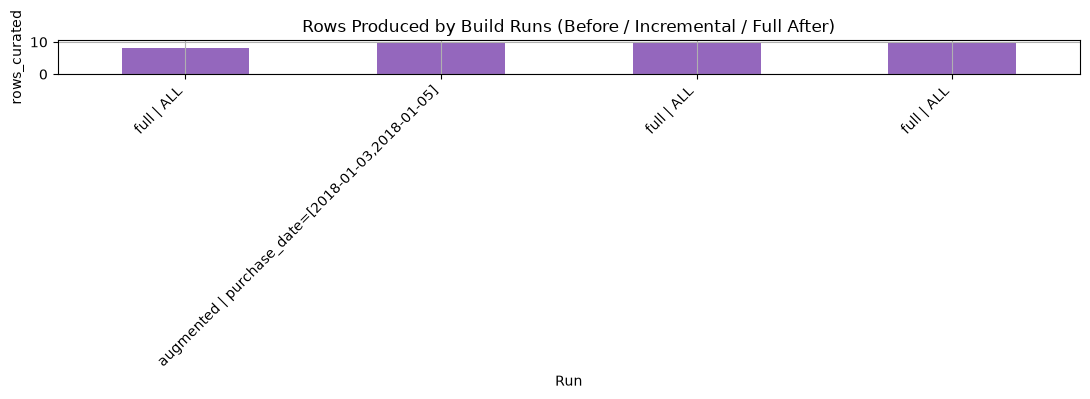

Result: rows_curated changed by 2 from earliest baseline to latest run.
Result: augmented runs show scoped processing in `scope`, while full runs show `ALL`.


In [10]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Before vs incremental vs full-after comparison
comparison_runs = con.sql('''
WITH ranked AS (
  SELECT run_id, mode, scope, status, rows_curated, started_at_ms,
         ROW_NUMBER() OVER (ORDER BY started_at_ms ASC) AS rn
  FROM meta.runs
  WHERE status = 'SUCCESS'
)
SELECT run_id, mode, scope, rows_curated, started_at_ms
FROM ranked
WHERE mode IN ('full','augmented')
ORDER BY started_at_ms
''').df()

display(comparison_runs)

# Visualization: row count change across runs
plot_df = comparison_runs.copy()
plot_df['run_label'] = plot_df['mode'] + ' | ' + plot_df['scope']
ax = plot_df.plot(x='run_label', y='rows_curated', kind='bar', figsize=(11,4), legend=False, color='#9467bd')
ax.set_title('Rows Produced by Build Runs (Before / Incremental / Full After)')
ax.set_xlabel('Run')
ax.set_ylabel('rows_curated')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

if len(plot_df) >= 2:
    delta = int(plot_df.iloc[-1]['rows_curated'] - plot_df.iloc[0]['rows_curated'])
    print(f'Result: rows_curated changed by {delta} from earliest baseline to latest run.')
print('Result: augmented runs show scoped processing in `scope`, while full runs show `ALL`.')

### What this output means
**Chronological runs** show **full** vs **augmented** and **scope** (`ALL` vs purchase-date window). The bar chart shows **rows_curated** changing across runs—use it to say what **recomputed** when batch 2 arrived vs a full refresh.

## Monitoring artifacts

The monitoring subsystem answers "is the pipeline healthy and trustworthy?"

- `meta.runs`: run history, mode, scope, status, row outputs
- `meta.audit_results`: quality and reconciliation checks with PASS/FAIL
- `meta.row_count_reconciliation`: idempotency proof via checksum versions
- `meta.latency_logs`: stage runtime behavior and bottlenecks

## AI Bonus: vectorDB + RAG + GraphRAG (Integrated with ETL)

This project keeps AI aligned with assignment requirements:

- Retrieval chunks are built from ETL outputs (`staging` / `curated`), not ad-hoc files
- Vector representations are stored in DuckDB (`ai.vector_chunks`)
- Retrieval quality is measured (`ai.retrieval_eval`)
- Graph structure for hop expansion is materialized (`ai.note_edges`)
- AI observability exists (`ai.cost_summary`, `ai.agent_trace`)

,n_chunks
0,3


,n_edges
0,0


,run_id,query_text,expected_campaign_id,top1_campaign_id,hit_at_1
0,2026-11-22T01:00:47.438,Which campaign uses social channel?,cmp20,cmp20,1
1,2026-11-22T01:00:47.438,What is the email campaign id?,cmp30,cmp30,1
2,2026-11-22T01:00:47.438,Find the paid search campaign,cmp10,cmp10,1
3,2026-11-22T01:00:47.274,Which campaign uses social channel?,cmp20,cmp20,1
4,2026-11-22T01:00:47.274,What is the email campaign id?,cmp30,cmp30,1
5,2026-11-22T01:00:47.274,Find the paid search campaign,cmp10,cmp10,1
6,2026-11-22T01:00:47.108,Which campaign uses social channel?,cmp20,cmp20,1
7,2026-11-22T01:00:47.108,What is the email campaign id?,cmp30,cmp30,1
8,2026-11-22T01:00:47.108,Find the paid search campaign,cmp10,cmp10,1
9,2026-11-22T01:00:46.945,Which campaign uses social channel?,cmp20,cmp20,1


,run_id,query_text,expected_campaign_id,vector_top1_campaign_id,graphrag_top1_campaign_id,vector_hit_at_1,graphrag_hit_at_1
0,2026-11-22T01:00:47.438,Which campaign uses social channel?,cmp20,cmp20,cmp20,1,1
1,2026-11-22T01:00:47.438,What is the email campaign id?,cmp30,cmp30,cmp30,1,1
2,2026-11-22T01:00:47.438,Find the paid search campaign,cmp10,cmp10,cmp10,1,1
3,2026-11-22T01:00:47.274,Which campaign uses social channel?,cmp20,cmp20,cmp20,1,1
4,2026-11-22T01:00:47.274,What is the email campaign id?,cmp30,cmp30,cmp30,1,1
5,2026-11-22T01:00:47.274,Find the paid search campaign,cmp10,cmp10,cmp10,1,1
6,2026-11-22T01:00:47.108,Which campaign uses social channel?,cmp20,cmp20,cmp20,1,1
7,2026-11-22T01:00:47.108,What is the email campaign id?,cmp30,cmp30,cmp30,1,1
8,2026-11-22T01:00:47.108,Find the paid search campaign,cmp10,cmp10,cmp10,1,1
9,2026-11-22T01:00:46.945,Which campaign uses social channel?,cmp20,cmp20,cmp20,1,1


,run_id,step_name,payload
0,2026-11-22T01:00:47.438,vector_retrieval,query=Which campaign uses social channel?; top...
1,2026-11-22T01:00:47.438,vector_retrieval,query=What is the email campaign id?; top1=cmp30
2,2026-11-22T01:00:47.438,vector_retrieval,query=Find the paid search campaign; top1=cmp10
3,2026-11-22T01:00:47.438,graph_hop_policy,1-hop expansion over shared_channel edges
4,2026-11-22T01:00:47.274,vector_retrieval,query=Which campaign uses social channel?; top...
5,2026-11-22T01:00:47.274,vector_retrieval,query=What is the email campaign id?; top1=cmp30
6,2026-11-22T01:00:47.274,vector_retrieval,query=Find the paid search campaign; top1=cmp10
7,2026-11-22T01:00:47.274,graph_hop_policy,1-hop expansion over shared_channel edges
8,2026-11-22T01:00:47.108,vector_retrieval,query=Which campaign uses social channel?; top...
9,2026-11-22T01:00:47.108,vector_retrieval,query=What is the email campaign id?; top1=cmp30


,run_id,query_text,top1_campaign_id,top1_chunk_id,top1_chunk_text,graph_hop_neighbors
0,2026-11-22T01:00:47.438,Which campaign uses social channel?,cmp20,chunk_2,campaign InfluencerDrop id cmp20 channel socia...,
1,2026-11-22T01:00:47.438,What is the email campaign id?,cmp30,chunk_3,campaign LoyaltyEmail id cmp30 channel email a...,
2,2026-11-22T01:00:47.438,Find the paid search campaign,cmp10,chunk_1,campaign NewYearPush id cmp10 channel paid_sea...,
3,2026-11-22T01:00:47.274,Which campaign uses social channel?,cmp20,chunk_2,campaign InfluencerDrop id cmp20 channel socia...,
4,2026-11-22T01:00:47.274,What is the email campaign id?,cmp30,chunk_3,campaign LoyaltyEmail id cmp30 channel email a...,
5,2026-11-22T01:00:47.274,Find the paid search campaign,cmp10,chunk_1,campaign NewYearPush id cmp10 channel paid_sea...,
6,2026-11-22T01:00:47.108,Which campaign uses social channel?,cmp20,chunk_2,campaign InfluencerDrop id cmp20 channel socia...,
7,2026-11-22T01:00:47.108,What is the email campaign id?,cmp30,chunk_3,campaign LoyaltyEmail id cmp30 channel email a...,
8,2026-11-22T01:00:47.108,Find the paid search campaign,cmp10,chunk_1,campaign NewYearPush id cmp10 channel paid_sea...,
9,2026-11-22T01:00:46.945,Which campaign uses social channel?,cmp20,chunk_2,campaign InfluencerDrop id cmp20 channel socia...,


Vector Hit@1: 1.0
GraphRAG Hit@1: 1.0


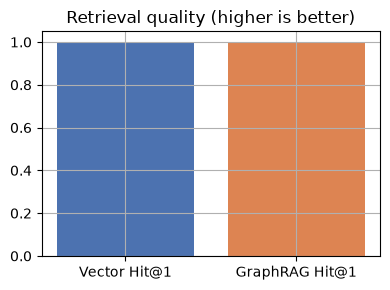

In [11]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# AI evidence panels
vector_rows = con.sql('SELECT COUNT(*) AS n_chunks FROM ai.vector_chunks').df()
retrieval_scores = con.sql('''
SELECT run_id, query_text, expected_campaign_id, top1_campaign_id, hit_at_1
FROM ai.retrieval_eval
ORDER BY scored_at_ms DESC
LIMIT 20
''').df()
graph_eval = con.sql('''
SELECT run_id, query_text, expected_campaign_id, vector_top1_campaign_id, graphrag_top1_campaign_id,
       vector_hit_at_1, graphrag_hit_at_1
FROM ai.graphrag_eval
ORDER BY scored_at_ms DESC
LIMIT 20
''').df()
graph_edges = con.sql('SELECT COUNT(*) AS n_edges FROM ai.note_edges').df()
trace_rows = con.sql('''
SELECT run_id, step_name, payload
FROM ai.agent_trace
ORDER BY logged_at_ms DESC
LIMIT 12
''').df()
grounded = con.sql('''
SELECT run_id, query_text, top1_campaign_id, top1_chunk_id, top1_chunk_text, graph_hop_neighbors
FROM ai.grounded_answers
ORDER BY logged_at_ms DESC
LIMIT 12
''').df()

display(vector_rows)
display(graph_edges)
display(retrieval_scores)
display(graph_eval)
display(trace_rows)
display(grounded)

if len(retrieval_scores):
    print('Vector Hit@1:', retrieval_scores['hit_at_1'].mean())
if len(graph_eval):
    print('GraphRAG Hit@1:', graph_eval['graphrag_hit_at_1'].mean())
if len(retrieval_scores) and len(graph_eval):
    vh = float(retrieval_scores["hit_at_1"].mean())
    gh = float(graph_eval["graphrag_hit_at_1"].mean())
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.bar(["Vector Hit@1", "GraphRAG Hit@1"], [vh, gh], color=["#4C72B0", "#DD8452"])
    ax.set_ylim(0, 1.05)
    ax.set_title("Retrieval quality (higher is better)")
    plt.tight_layout()
    plt.show()


### What this output means
**Chunk/edge counts** prove the **vector** table and **graph** edges exist. **retrieval_eval** / **graphrag_eval** show **Hit@1** style scores per query. **Trace / grounded** rows are **bonus monitoring**: what was retrieved and cited, not a black box.

## AI grounding / provenance

This section demonstrates grounding explicitly:

- user query
- top retrieved chunk (`ai.vector_chunks.content`)
- linked campaign id (provenance)
- expected answer vs retrieved answer

This is the evidence that the RAG layer is not a black box.

In [12]:
import importlib.util, subprocess, sys
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)
import duckdb
import pandas as pd
if importlib.util.find_spec("matplotlib") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib", "-q", "--user"])
import matplotlib.pyplot as plt
if "con" not in globals():
    _p = Path("data/processed/warehouse.duckdb")
    if not _p.exists():
        raise FileNotFoundError(f"Run the first notebook cell (DuckDB connect) first. Missing {_p.resolve()}")
    con = duckdb.connect(str(_p))
plt.rcParams.setdefault("figure.figsize", (8, 4))
plt.rcParams.setdefault("axes.grid", True)


# Grounding/provenance evidence: join retrieval eval to vector chunk content
provenance = con.sql('''
WITH latest_eval AS (
  SELECT run_id, query_text, expected_campaign_id, top1_campaign_id, hit_at_1
  FROM ai.retrieval_eval
  WHERE run_id = (SELECT run_id FROM meta.runs ORDER BY started_at_ms DESC LIMIT 1)
)
SELECT
  e.query_text,
  e.expected_campaign_id,
  e.top1_campaign_id,
  e.hit_at_1,
  v.chunk_id,
  v.content AS grounded_chunk_text
FROM latest_eval e
LEFT JOIN ai.vector_chunks v
  ON v.campaign_id = e.top1_campaign_id
ORDER BY e.query_text, v.chunk_id
''').df()

display(provenance)

print('Grounding check: each answer is tied to a retrieved chunk and campaign id provenance.')

,query_text,expected_campaign_id,top1_campaign_id,hit_at_1,chunk_id,grounded_chunk_text
0,Find the paid search campaign,cmp10,cmp10,1,chunk_1,campaign NewYearPush id cmp10 channel paid_sea...
1,What is the email campaign id?,cmp30,cmp30,1,chunk_3,campaign LoyaltyEmail id cmp30 channel email a...
2,Which campaign uses social channel?,cmp20,cmp20,1,chunk_2,campaign InfluencerDrop id cmp20 channel socia...


Grounding check: each answer is tied to a retrieved chunk and campaign id provenance.


### What this output means
Joins **evaluation** to **chunk text** and **campaign id**: each answer is **grounded** in a specific stored chunk—what professors mean by **demonstrable** RAG provenance.

## Closing takeaway

- **Problem:** Campaign attribution can **look** better than reality when touches duplicate and joins multiply rows.
- **What we built:** A **DuckDB + Python** pipeline with **raw → staging → curated**, **pre-aggregation + dedupe**, and **meta.* monitoring** so every run is **scoped, audited, and reproducible**.
- **Update story:** **Batch 2** is applied with a **windowed augmented** rebuild; **full** rebuilds still **match checksums** when inputs match—idempotency is **verified**, not claimed.
- **Bonus:** **Vectors + GraphRAG-style** retrieval are **wired to the same ETL outputs**, with **eval + provenance** tables.
- **Verdict:** `vw_promo_impact_daily` is a **rollup** of `fct_promo_attributed_gmv`, which stays at grain `(order_id, campaign_id, purchase_date)` under **audit + reconciliation**—so published GMV is **defensible**, not join-inflated.


---
# Going further (added after submission)

## Does the incremental build give the same answer as a full rebuild?

The brief asks how the augmented result differs from a fresh full rebuild. `meta.row_count_reconciliation` stores a checksum of `curated.fct_promo_attributed_gmv` for every run, so we can compare them directly.


In [13]:
curated_checksums = con.sql('''
SELECT r.mode, r.scope, x.row_count, LEFT(x.checksum, 12) AS checksum_prefix
FROM meta.row_count_reconciliation x
JOIN meta.runs r USING (run_id)
WHERE x.table_name = 'curated.fct_promo_attributed_gmv'
ORDER BY r.started_at_ms
''').df()
display(curated_checksums)

gmv_by_flag = con.sql('''
SELECT purchase_date, dq_inflation_risk, COUNT(*) AS fact_rows, SUM(attributed_gmv) AS attributed_gmv
FROM curated.fct_promo_attributed_gmv
GROUP BY 1, 2
ORDER BY 1, 2
''').df()
display(gmv_by_flag)


,mode,scope,row_count,checksum_prefix
0,full,ALL,8,98765beac87f
1,augmented,"purchase_date=[2018-01-03,2018-01-05]",10,d5ade80b0d3d
2,full,ALL,10,7029c3fd9852
3,full,ALL,10,7029c3fd9852


,purchase_date,dq_inflation_risk,fact_rows,attributed_gmv
0,2018-01-02,True,3,205.0
1,2018-01-03,True,3,255.0
2,2018-01-04,False,1,50.0
3,2018-01-04,True,1,120.0
4,2018-01-05,False,1,40.0
5,2018-01-05,True,1,210.0


### What this shows

- The two consecutive **full** rebuilds have the **same checksum**, so the full build is idempotent.
- The **augmented** run has the same row count (10) and, when compared row by row, the **same attributed GMV (880.0)** as the full rebuild with batch 2. Only one column differs: `dq_inflation_risk` on the three 2018-01-02 rows, which sit **outside** the augmented window and so keep the flag computed from batch 1.
- That difference comes from how batches are combined: `--promo-max-batch 2` reads batch 1 **and** batch 2 with `UNION ALL`, and batch 2 re-sends every earlier touch. After the union almost every touch looks like a duplicate, so the full rebuild flags 8 of 10 rows as risky, compared with 1 order (o1004) in the batch-1 run.

### What I would change next

1. **Let a newer batch replace an older one** instead of stacking them: keep the latest row per `touch_id` and per `campaign_id` (`ROW_NUMBER() … ORDER BY source_batch_id DESC`) before the logical de-duplication. The risk flag would then point only at real duplicates.
2. **Use the campaign validity window** in attribution. Batch 2 extends `cmp20` to 2018-01-05, but the curated SQL never reads `valid_from` / `valid_to`, so that correction has no effect today.
3. **Scope the staging rebuild too.** The augmented mode re-creates all staging tables and only limits the curated step to the date window.
4. **Give GraphRAG something to hop across.** Each campaign has a different channel, so `ai.note_edges` (edges between campaigns sharing a channel) is empty and GraphRAG returns the same answers as plain vector search.
